# Finding 4: Replication Across Datasets

**Research question:** Is the relationship between parental income and adult earnings consistent across NLSY97 and Opportunity Insights?

**Plan:** estimate the same rank–rank relationship in both datasets — adult earnings rank regressed on parental income rank — and compare the slopes and the mean adult rank in each parental income quintile. Then run robustness checks with a different adult outcome (household rank, age 26) and separately by sex.

In [1]:
import polars as pl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import statsmodels.formula.api as smf
from decimal import Decimal, ROUND_HALF_UP

# Slope per 10 percentile points, from the slope rounded to 4 decimals,
# formatted with half-up rounding -- the same convention Finding 1 uses
# (its 0.2945 slope is reported as 2.95 per 10 points).
def per10(value):
    return Decimal(str(round(value, 4) * 10)).quantize(
        Decimal("0.01"), rounding=ROUND_HALF_UP)

# Load NLSY97 dataset
nlsy97 = pl.read_csv("data/raw/nlsy97/NLSY97_expanded.csv")
print("Dataset shape:", nlsy97.shape)
print("Columns:", nlsy97.columns)

Dataset shape: (8984, 12)
Columns: ['R0000100', 'R0536300', 'R0536401', 'R0536402', 'R1204500', 'R1235800', 'R1302400', 'R1302500', 'R1482600', 'U5753300', 'U5753500', 'Z9061911']


In [2]:
# Convert to pandas for statsmodels regression
df = nlsy97.to_pandas()

# Replace NLSY97 special missing-value codes (same cleaning as Finding 1)
missing_codes = [-1, -2, -3, -4, -5]
for col in ["R1204500", "U5753500", "U5753300", "R1302400", "R1302500"]:
    df[col] = df[col].replace(missing_codes, np.nan)

# Respondents who explicitly reported no job income
# are assigned zero wages when wages were skipped
no_income = df["U5753300"] == 0
df.loc[no_income & df["U5753500"].isna(), "U5753500"] = 0

# Keep respondents with valid childhood income
# and positive reported adult wages
analysis_df = df.loc[
    df["R1204500"].notna() &
    (df["U5753500"] > 0)
].copy()

# Percentile ranks among the selected earners.
# R1204500 = gross family income in 1997 (childhood/parental income)
# U5753500 = adult wages/salary in 2021 (respondents born 1980-1984,
# so about ages 37-41)
analysis_df["parent_income_rank"] = (
    analysis_df["R1204500"].rank(pct=True) * 100
)
analysis_df["child_income_rank"] = (
    analysis_df["U5753500"].rank(pct=True) * 100
)
print("Respondents included in regression:", len(analysis_df))

Respondents included in regression: 3847


In [3]:
# NLSY97 rank-rank regression (reproduces Finding 1)
nlsy_model = smf.ols(
    "child_income_rank ~ parent_income_rank",
    data=analysis_df
).fit()
nlsy_slope = nlsy_model.params["parent_income_rank"]
nlsy_lo, nlsy_hi = nlsy_model.conf_int().loc["parent_income_rank"]
print(f"NLSY97 slope: {nlsy_slope:.4f} per percentile point")
print(f"  per 10 points: {per10(nlsy_slope)} "
      f"(95% CI: {per10(nlsy_lo)}-{per10(nlsy_hi)})")
print(f"  p-value: {nlsy_model.pvalues['parent_income_rank']:.3g}")
print(f"  R-squared: {nlsy_model.rsquared:.4f}")
print(f"  n = {int(nlsy_model.nobs)}")

NLSY97 slope: 0.2945 per percentile point
  per 10 points: 2.95 (95% CI: 2.64-3.25)
  p-value: 7.73e-78
  R-squared: 0.0867
  n = 3847


## Opportunity Insights: the comparable measures

Opportunity Insights (`data/raw/opportunity_insights/gender_nat.xls`, Online Data Table 3) is not individual-level data: it has one row per parental income percentile (100 rows), reporting mean adult outcomes from national tax records, separately for women (`_f`) and men (`_m`).

| Concept | NLSY97 | Opportunity Insights |
|---|---|---|
| Parental income | Rank of 1997 gross family income (`R1204500`), within the 3,847 positive earners | National parental household income percentile (`par_pctile`, 1–100) |
| Adult earnings | Rank of 2021 wages/salary (`U5753500`), within the 3,847 positive earners | Mean national individual income rank at age 30 (`kid_indv_rank_30`, 0–1, ×100), averaged across women and men |
| Unit of analysis | 3,847 individuals | 100 parental percentiles (group means) |
| Adult age | About 37–41 in 2021 | 30 |

The slopes are comparable because both are rank–rank slopes in percentile points. Two things are **not** comparable: the R² values (averaging into 100 group means removes most individual variation, so the Opportunity Insights R² is near 1 by construction) and the width of the confidence intervals (the Opportunity Insights interval comes from fitting 100 means, not individuals).

In [4]:
# Load Opportunity Insights (one row per parental income percentile)
oi = pd.read_excel("data/raw/opportunity_insights/gender_nat.xls")
print("Opportunity Insights shape:", oi.shape)
print("Parental percentiles:", oi["par_pctile"].min(), "to", oi["par_pctile"].max())
print("Missing values:", int(oi.isna().sum().sum()))

# Mean national individual income rank at age 30, in percentile points.
# The file reports ranks as fractions (0-1), separately by sex,
# so average the two sexes and multiply by 100.
oi["kid_rank_pp"] = (oi["kid_indv_rank_30_f"] + oi["kid_indv_rank_30_m"]) / 2 * 100
oi["kid_rank_f_pp"] = oi["kid_indv_rank_30_f"] * 100
oi["kid_rank_m_pp"] = oi["kid_indv_rank_30_m"] * 100

def report(name, model):
    slope = model.params["par_pctile"]
    lo, hi = model.conf_int().loc["par_pctile"]
    print(f"{name}: slope {slope:.4f} per point "
          f"({per10(slope)} per 10 points; "
          f"95% CI: {per10(lo)}-{per10(hi)}), "
          f"p = {model.pvalues['par_pctile']:.3g}, "
          f"R2 = {model.rsquared:.4f}, n = {int(model.nobs)}")
    return slope, lo, hi

oi_model = smf.ols("kid_rank_pp ~ par_pctile", data=oi).fit()
oi_slope, oi_lo, oi_hi = report("OI pooled (women + men)", oi_model)
oi_f_model = smf.ols("kid_rank_f_pp ~ par_pctile", data=oi).fit()
oi_f_slope, oi_f_lo, oi_f_hi = report("OI women", oi_f_model)
oi_m_model = smf.ols("kid_rank_m_pp ~ par_pctile", data=oi).fit()
oi_m_slope, oi_m_lo, oi_m_hi = report("OI men", oi_m_model)
print(f"\nOI pooled slope inside NLSY97 95% CI "
      f"[{nlsy_lo:.4f}, {nlsy_hi:.4f}]: {nlsy_lo <= oi_slope <= nlsy_hi}")

Opportunity Insights shape: (100, 25)
Parental percentiles: 1 to 100
Missing values: 0
OI pooled (women + men): slope 0.2773 per point (2.77 per 10 points; 95% CI: 2.73-2.81), p = 3.91e-113, R2 = 0.9947, n = 100
OI women: slope 0.2488 per point (2.49 per 10 points; 95% CI: 2.43-2.55), p = 2.99e-90, R2 = 0.9843, n = 100
OI men: slope 0.3057 per point (3.06 per 10 points; 95% CI: 2.99-3.12), p = 1.42e-97, R2 = 0.9889, n = 100

OI pooled slope inside NLSY97 95% CI [0.2642, 0.3247]: True


/tmp/ipykernel_3664/222995285.py:2: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  oi = pd.read_excel("data/raw/opportunity_insights/gender_nat.xls")


## Robustness check 1: comparable income groups

Compare the mean adult earnings rank in each parental income quintile. If the relationship replicates, the two datasets should show a similar climb from the bottom to the top quintile, not just similar slopes.

In [5]:
# Quintile means in each dataset
analysis_df["income_quintile"] = pd.qcut(
    analysis_df["parent_income_rank"], 5,
    labels=["Q1 (lowest)", "Q2", "Q3", "Q4", "Q5 (highest)"]
)
nlsy_q = analysis_df.groupby("income_quintile", observed=True)["child_income_rank"].agg(
    ["mean", "std", "count"]
)
nlsy_q["se"] = nlsy_q["std"] / np.sqrt(nlsy_q["count"])
nlsy_q["ci_low"] = nlsy_q["mean"] - 1.96 * nlsy_q["se"]
nlsy_q["ci_high"] = nlsy_q["mean"] + 1.96 * nlsy_q["se"]

oi["income_quintile"] = pd.qcut(
    oi["par_pctile"], 5,
    labels=["Q1 (lowest)", "Q2", "Q3", "Q4", "Q5 (highest)"]
)
oi_q = oi.groupby("income_quintile", observed=True)["kid_rank_pp"].mean()

quintile_table = pd.DataFrame({
    "NLSY97 mean adult rank": nlsy_q["mean"].round(2),
    "NLSY97 95% CI low": nlsy_q["ci_low"].round(2),
    "NLSY97 95% CI high": nlsy_q["ci_high"].round(2),
    "OI mean adult rank": oi_q.round(2),
})
print(quintile_table)
print(f"\nQ5 - Q1 gap: NLSY97 "
      f"{nlsy_q['mean'].iloc[-1] - nlsy_q['mean'].iloc[0]:.1f} points, "
      f"OI {oi_q.iloc[-1] - oi_q.iloc[0]:.1f} points")

                 NLSY97 mean adult rank  NLSY97 95% CI low  \
income_quintile                                              
Q1 (lowest)                       37.14              35.29   
Q2                                46.36              44.47   
Q3                                48.43              46.44   
Q4                                56.42              54.42   
Q5 (highest)                      61.74              59.73   

                 NLSY97 95% CI high  OI mean adult rank  
income_quintile                                          
Q1 (lowest)                   38.99               38.68  
Q2                            48.25               45.02  
Q3                            50.42               50.10  
Q4                            58.42               55.14  
Q5 (highest)                  63.76               61.21  

Q5 - Q1 gap: NLSY97 24.6 points, OI 22.5 points


## Robustness check 2: alternative specifications and sex splits

- Opportunity Insights with a different adult outcome: household income rank at age 30 (`kid_rank_30`, includes a spouse's earnings) and individual rank at age 26 (`kid_indv_rank_26`).
- Both datasets split by sex: NLSY97 uses `R0536300` (1 = Male, 2 = Female); Opportunity Insights already reports women and men separately.

In [6]:
# OI alternative outcomes (pooled across sexes, percentile points)
oi["kid_household_rank_pp"] = (oi["kid_rank_30_f"] + oi["kid_rank_30_m"]) / 2 * 100
oi["kid_rank_26_pp"] = (oi["kid_indv_rank_26_f"] + oi["kid_indv_rank_26_m"]) / 2 * 100
alt_household = smf.ols("kid_household_rank_pp ~ par_pctile", data=oi).fit()
report("OI household rank at 30", alt_household)
alt_26 = smf.ols("kid_rank_26_pp ~ par_pctile", data=oi).fit()
report("OI individual rank at 26", alt_26)

# NLSY97 by sex
for sex_code, label in [(1, "Male"), (2, "Female")]:
    sub = analysis_df[analysis_df["R0536300"] == sex_code]
    m = smf.ols("child_income_rank ~ parent_income_rank", data=sub).fit()
    print(f"NLSY97 {label}: n = {int(m.nobs)}, "
          f"slope {m.params['parent_income_rank']:.4f} "
          f"(95% CI: {m.conf_int().loc['parent_income_rank', 0]:.4f}-"
          f"{m.conf_int().loc['parent_income_rank', 1]:.4f})")

OI household rank at 30: slope 0.3299 per point (3.30 per 10 points; 95% CI: 3.25-3.35), p = 1.06e-113, R2 = 0.9948, n = 100
OI individual rank at 26: slope 0.2589 per point (2.59 per 10 points; 95% CI: 2.53-2.64), p = 2.58e-97, R2 = 0.9888, n = 100
NLSY97 Male: n = 1941, slope 0.3066 (95% CI: 0.2648-0.3484)
NLSY97 Female: n = 1906, slope 0.2727 (95% CI: 0.2312-0.3142)


## Figure: Finding 4

Panel A compares mean adult earnings rank by parental income quintile. Panel B compares the rank–rank slopes (per 10-percentile-point increase in parental income rank) with 95% confidence intervals. The Opportunity Insights intervals are narrow because they come from fitting 100 percentile means, not individuals.

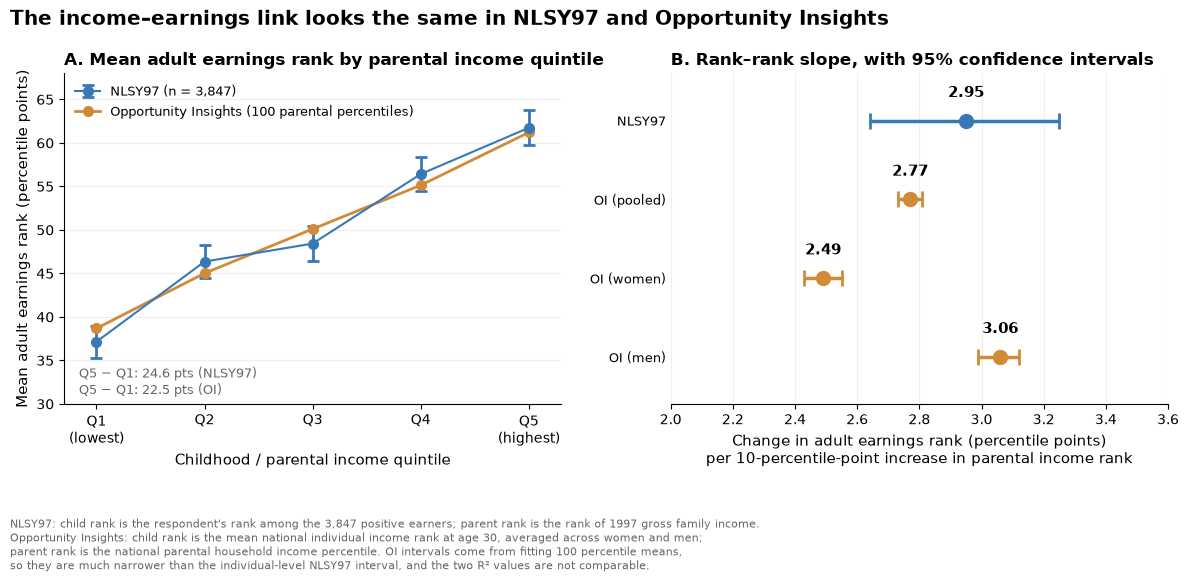

In [7]:
BLUE = "#3978B7"
ORANGE = "#D18A37"
GREY = "#666666"

quintile_labels = ["Q1\n(lowest)", "Q2", "Q3", "Q4", "Q5\n(highest)"]
x = np.arange(5)
nlsy_mean = nlsy_q["mean"].values
nlsy_err = np.array([nlsy_mean - nlsy_q["ci_low"].values,
                     nlsy_q["ci_high"].values - nlsy_mean])
oi_mean = oi_q.values

slope_labels = ["NLSY97", "OI (pooled)", "OI (women)", "OI (men)"]
slopes = np.array([float(per10(s)) for s in
                    [nlsy_slope, oi_slope, oi_f_slope, oi_m_slope]])
slope_lo = np.array([float(per10(s)) for s in
                     [nlsy_lo, oi_lo, oi_f_lo, oi_m_lo]])
slope_hi = np.array([float(per10(s)) for s in
                     [nlsy_hi, oi_hi, oi_f_hi, oi_m_hi]])
slope_colors = [BLUE, ORANGE, ORANGE, ORANGE]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.8))
fig.suptitle("The income\u2013earnings link looks the same in NLSY97 and Opportunity Insights",
             fontsize=14.5, fontweight="bold", x=0.015, ha="left")

h1 = ax1.errorbar(x, nlsy_mean, yerr=nlsy_err, fmt="o-", color=BLUE,
                  markersize=7, capsize=4, elinewidth=2, capthick=2,
                  label="NLSY97 (n = 3,847)", zorder=3)
h2, = ax1.plot(x, oi_mean, "o-", color=ORANGE, markersize=7, linewidth=2,
               label="Opportunity Insights (100 parental percentiles)", zorder=3)
ax1.set_xticks(x)
ax1.set_xticklabels(quintile_labels, fontsize=10)
ax1.set_ylim(30, 68)
ax1.set_xlim(-0.3, 4.3)
ax1.set_ylabel("Mean adult earnings rank (percentile points)", fontsize=11)
ax1.set_xlabel("Childhood / parental income quintile", fontsize=11)
ax1.set_title("A. Mean adult earnings rank by parental income quintile",
              fontsize=12, fontweight="bold", loc="left")
ax1.grid(axis="y", alpha=0.2)
ax1.set_axisbelow(True)
for spine in ["top", "right"]:
    ax1.spines[spine].set_visible(False)
ax1.legend(handles=[h1, h2], fontsize=9, loc="upper left", frameon=False)
ax1.annotate(f"Q5 \u2212 Q1: {nlsy_mean[-1] - nlsy_mean[0]:.1f} pts (NLSY97)\n"
             f"Q5 \u2212 Q1: {oi_mean[-1] - oi_mean[0]:.1f} pts (OI)",
             xy=(0.03, 0.03), xycoords="axes fraction", fontsize=9, color=GREY)

ypos = [3, 2, 1, 0]
for i in range(4):
    ax2.errorbar(slopes[i], ypos[i],
                 xerr=[[slopes[i] - slope_lo[i]], [slope_hi[i] - slopes[i]]],
                 fmt="o", color=slope_colors[i], markersize=10, capsize=6,
                 elinewidth=2.5, capthick=2, zorder=3)
    ax2.text(slopes[i], ypos[i] + 0.30, f"{slopes[i]:.2f}",
             ha="center", fontsize=11, fontweight="bold")
ax2.set_yticks(ypos)
ax2.set_yticklabels(slope_labels, fontsize=9.5)
ax2.set_xlim(2.0, 3.6)
ax2.set_ylim(-0.6, 3.6)
ax2.set_xlabel("Change in adult earnings rank (percentile points)\n"
               "per 10-percentile-point increase in parental income rank", fontsize=10.5)
ax2.set_title("B. Rank\u2013rank slope, with 95% confidence intervals",
              fontsize=12, fontweight="bold", loc="left")
ax2.grid(axis="x", alpha=0.2)
ax2.set_axisbelow(True)
for spine in ["top", "right", "left"]:
    ax2.spines[spine].set_visible(False)
ax2.tick_params(axis="y", length=0)

fig.text(0.015, 0.015,
         "NLSY97: child rank is the respondent's rank among the 3,847 positive earners; "
         "parent rank is the rank of 1997 gross family income.\n"
         "Opportunity Insights: child rank is the mean national individual income rank at age 30, "
         "averaged across women and men;\n"
         "parent rank is the national parental household income percentile. OI intervals come from "
         "fitting 100 percentile means,\n"
         "so they are much narrower than the individual-level NLSY97 interval, and the two "
         "R\u00b2 values are not comparable.",
         fontsize=8, color=GREY)
plt.subplots_adjust(left=0.06, right=0.98, top=0.87, bottom=0.30, wspace=0.22)

Path("figures").mkdir(exist_ok=True)
plt.savefig("figures/finding-four.png", dpi=300)
plt.show()

## Finding 4 — summary

**One-sentence finding:** Across two independent sources, the parental-income/adult-earnings link is nearly identical: a 10-percentile-point increase in parental income rank was associated with a 2.95-percentile-point increase in adult earnings rank in NLSY97 (95% CI: 2.64–3.25; n = 3,847) and a 2.77-point increase in Opportunity Insights (95% CI: 2.73–2.81; 100 parental percentiles).

The Opportunity Insights slope sits inside the NLSY97 confidence interval, and the quintile patterns match as well (mean adult rank rises from about 37–39 in the bottom quintile to about 61–62 in the top in both datasets). The pattern survived robustness checks using household rank at age 30, individual rank at age 26, and separate estimates for women and men in both datasets. The datasets still differ in important ways — NLSY97 ranks are within its own sample of positive earners measured at about ages 37–41, while Opportunity Insights ranks are national, include zero earners, and measure earnings at age 30 — and because both sources are observational, this replication strengthens the association without showing that parental income causes adult earnings.